# Лабораторная работа №9: Fine-tuning VLM с помощью LLaMA-Factory

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Преобразовать мультимодальные данные в instruction format.
- Сформировать QLoRA YAML и запустить SFT.
- Сравнить base и adapter, включая OOD slice.


## Теоретическая часть

SFT минимизирует autoregressive loss только на целевом ответе. QLoRA хранит base weights в 4-bit NF4 и обучает low-rank update $\Delta W=BA$, что уменьшает память. LLaMA-Factory фиксирует pipeline в YAML-конфигурации.


### Математическая постановка

$$W'=W_q+\frac{\alpha}{r}BA,\quad B\in\mathbb R^{d\times r},\ A\in\mathbb R^{r\times k}.$$ Обучаются только $A,B$; сравнение проводится с той же base model и evaluation set.


### Материалы

- [LLaMA-Factory](https://github.com/hiyouga/LLaMA-Factory)
- [QLoRA](https://arxiv.org/abs/2305.14314)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практический протокол

Вход — лицензированный предметный корпус `data/lab9/manifest.jsonl` с независимыми train/validation/ID/OOD. Получение и экспертная проверка данных обязательны; файл не заменяется выдуманным изображением. В Colab установите совместимый LLaMA-Factory из зафиксированного commit и запишите commit в отчёт. CLI запускается непосредственно из ноутбука. Полный режим означает фактическое обучение и сравнение; `FAST_DEV_RUN` обучает два шага только для проверки стека. Оценку общей способности выполните на отдельном общем VQA-наборе с заранее выбранной метрикой.

In [1]:
from pathlib import Path
import json, os, random, time
import numpy as np
SEED = 42
FAST_DEV_RUN = False  # True: проверка механики на малой выборке, НЕ отчётный эксперимент
ARTIFACTS = Path('artifacts'); ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
def save_json(name, data):
    (ARTIFACTS/name).write_text(json.dumps(data, ensure_ascii=False, indent=2, default=str))
from pathlib import Path
import json, hashlib
from datasets import load_dataset

SCIENCEQA_ID = 'derek-thomas/ScienceQA'
SCIENCEQA_REVISION = 'f18b0a70359ebfb41f658fd564208d0355b013f4'

def prepare_scienceqa(directory, smoke=False):
    """Fixed official splits, image-level deduplication, explicitly defined shifts."""
    directory = Path(directory).resolve(); directory.mkdir(parents=True, exist_ok=True)
    manifest = directory / ('manifest-smoke.jsonl' if smoke else 'manifest.jsonl')
    limits = {'train': 8 if smoke else 512, 'validation': 4 if smoke else 64,
              'id_test': 4 if smoke else 64, 'ood_test': 4 if smoke else 64,
              'general_test': 4 if smoke else 64}
    if manifest.exists():
        records = [json.loads(s) for s in manifest.read_text().splitlines()]
        if all(Path(r['image']).is_file() for r in records) and all(sum(r['split']==s for r in records)==n for s,n in limits.items()):
            return manifest
    records, seen, counts = [], set(), dict.fromkeys(limits, 0)
    for official in ('train', 'validation', 'test'):
        data = load_dataset(SCIENCEQA_ID, revision=SCIENCEQA_REVISION, split=official, streaming=True)
        for index, row in enumerate(data):
            image = row['image']
            if image is None: continue
            if official != 'test':
                if row['subject'] != 'natural science' or int(row['grade'].removeprefix('grade')) > 6: continue
                split = official
            elif row['subject'] != 'natural science': split = 'general_test'
            elif int(row['grade'].removeprefix('grade')) > 6: split = 'ood_test'
            else: split = 'id_test'
            if counts[split] >= limits[split]: continue
            image = image.convert('RGB')
            digest = hashlib.sha256(str(image.size).encode()+image.tobytes()).hexdigest()
            if digest in seen: continue
            seen.add(digest)
            path = directory / f'{digest}.png'; image.save(path)
            answer = int(row['answer']); choices = row['choices']
            question = row['question']+'\n'+'\n'.join(f'{chr(65+i)}. {v}' for i,v in enumerate(choices))+'\nReturn only the letter of the correct option.'
            records.append({'id': f'scienceqa-{official}-{index}', 'split': split,
                            'image': str(path), 'question': question, 'answer': chr(65+answer),
                            'choices': choices, 'answer_index': answer, 'label_type': 'multiple_choice',
                            'license': 'MIT (code license, lupantech/ScienceQA)',
                            'source_url': f'https://huggingface.co/datasets/{SCIENCEQA_ID}/tree/{SCIENCEQA_REVISION}',
                            'subject':row['subject'], 'grade':row['grade'], 'image_sha256':digest})
            counts[split] += 1
            required = [official] if official != 'test' else ['id_test','ood_test','general_test']
            if all(counts[s] == limits[s] for s in required): break
    if counts != limits: raise RuntimeError(f'Insufficient licensed image examples: {counts}; expected {limits}')
    manifest.write_text('\n'.join(json.dumps(r,ensure_ascii=False) for r in records)+'\n')
    (directory/'ATTRIBUTION.md').write_text('ScienceQA — Lu et al., NeurIPS 2022. Dataset distribution: '+SCIENCEQA_ID+'\nRevision: '+SCIENCEQA_REVISION+'\nDataset-card license: CC-BY-SA-4.0, https://creativecommons.org/licenses/by-sa/4.0/\nOriginal project: https://scienceqa.github.io/\nImage subsets and manifests retain attribution; downloaded images are not committed to this course.\nID: natural science grades 1–6; OOD: natural science grades 7–12; general: other subjects. This is an operational shift, not a claim of universal model ability.\n')
    return manifest


## Оценивание

Десять обязательных предметных этапов — по 1 баллу каждый, всего 10 баллов. Отдельное творческое исследование — до 1 дополнительного балла. Каждый этап принимается по указанному наблюдаемому результату.

### Манифест и независимые разбиения

*Вес: 1 балл.*

**Постановка.** Загрузите ScienceQA функцией prepare_scienceqa. Сформируйте 512 train и по 64 validation, ID, OOD и general примера с изображениями. ID: natural science, классы 1–6; OOD: тот же предмет, классы 7–12; general: другие предметы. Используйте официальные split и исключите повторные изображения по хешу.

**Результат.** manifest.jsonl и ATTRIBUTION.md.

**Критерий принятия.** Количество записей соответствует протоколу; ни одно изображение не используется в двух разбиениях; версия и лицензия источника указаны.


In [2]:
import torch, transformers, sys, subprocess, re, shutil
DATA_ROOT = Path(os.getenv("CV_COURSE_DATA", str(Path.cwd().parents[1] / "data")))
LAB9_DIR = DATA_ROOT / "lab9"
manifest_path = prepare_scienceqa(LAB9_DIR, smoke=FAST_DEV_RUN)
records = [json.loads(s) for s in manifest_path.read_text().splitlines()]
EXPECTED = {"train": 8, "validation": 4, "id_test": 4, "ood_test": 4, "general_test": 4} if FAST_DEV_RUN else \
           {"train": 512, "validation": 64, "id_test": 64, "ood_test": 64, "general_test": 64}
counts = {s: sum(r["split"] == s for r in records) for s in EXPECTED}
assert counts == EXPECTED, counts
by_split = {s: {r["image_sha256"] for r in records if r["split"] == s} for s in EXPECTED}
overlap = {f"{a}&{b}": len(by_split[a] & by_split[b]) for a in EXPECTED for b in EXPECTED if a < b}
assert not any(overlap.values()), "одно изображение попало в два разбиения"
assert (LAB9_DIR / "ATTRIBUTION.md").exists()
print(counts, "| пересечений по хешу изображений нет")
print((LAB9_DIR / "ATTRIBUTION.md").read_text()[:400])

{'train': 512, 'validation': 64, 'id_test': 64, 'ood_test': 64, 'general_test': 64} | пересечений по хешу изображений нет
ScienceQA — Lu et al., NeurIPS 2022. Dataset distribution: derek-thomas/ScienceQA
Revision: f18b0a70359ebfb41f658fd564208d0355b013f4
Dataset-card license: CC-BY-SA-4.0, https://creativecommons.org/licenses/by-sa/4.0/
Original project: https://scienceqa.github.io/
Image subsets and manifests retain attribution; downloaded images are not committed to this course.
ID: natural science grades 1–6; OOD:


### Визуальный аудит корпуса

*Вес: 1 балл.*

**Постановка.** Декодируйте изображения и постройте сетку примеров с вопросами и правильными буквами. Подсчитайте распределение ответов по каждому split: возможный перевес одной буквы следует учитывать при интерпретации accuracy.

**Результат.** data_profile.json и data_preview.png.

**Критерий принятия.** Показаны реальные изображения; правильная буква соответствует индексированному варианту; представлены частоты всех букв отдельно по split.


train         n=512 буквы={'A': 209, 'B': 230, 'C': 72, 'D': 1} доля частой=0.45 классы=['grade2', 'grade3', 'grade4']...
validation    n= 64 буквы={'A': 24, 'B': 32, 'C': 8} доля частой=0.50 классы=['grade2', 'grade3', 'grade4']...
id_test       n= 64 буквы={'A': 26, 'B': 27, 'C': 11} доля частой=0.42 классы=['grade2', 'grade3', 'grade4']...
ood_test      n= 64 буквы={'A': 25, 'B': 27, 'C': 9, 'D': 3} доля частой=0.42 классы=['grade7', 'grade8']...
general_test  n= 64 буквы={'A': 13, 'B': 21, 'C': 17, 'D': 13} доля частой=0.33 классы=['grade12', 'grade2', 'grade3']...


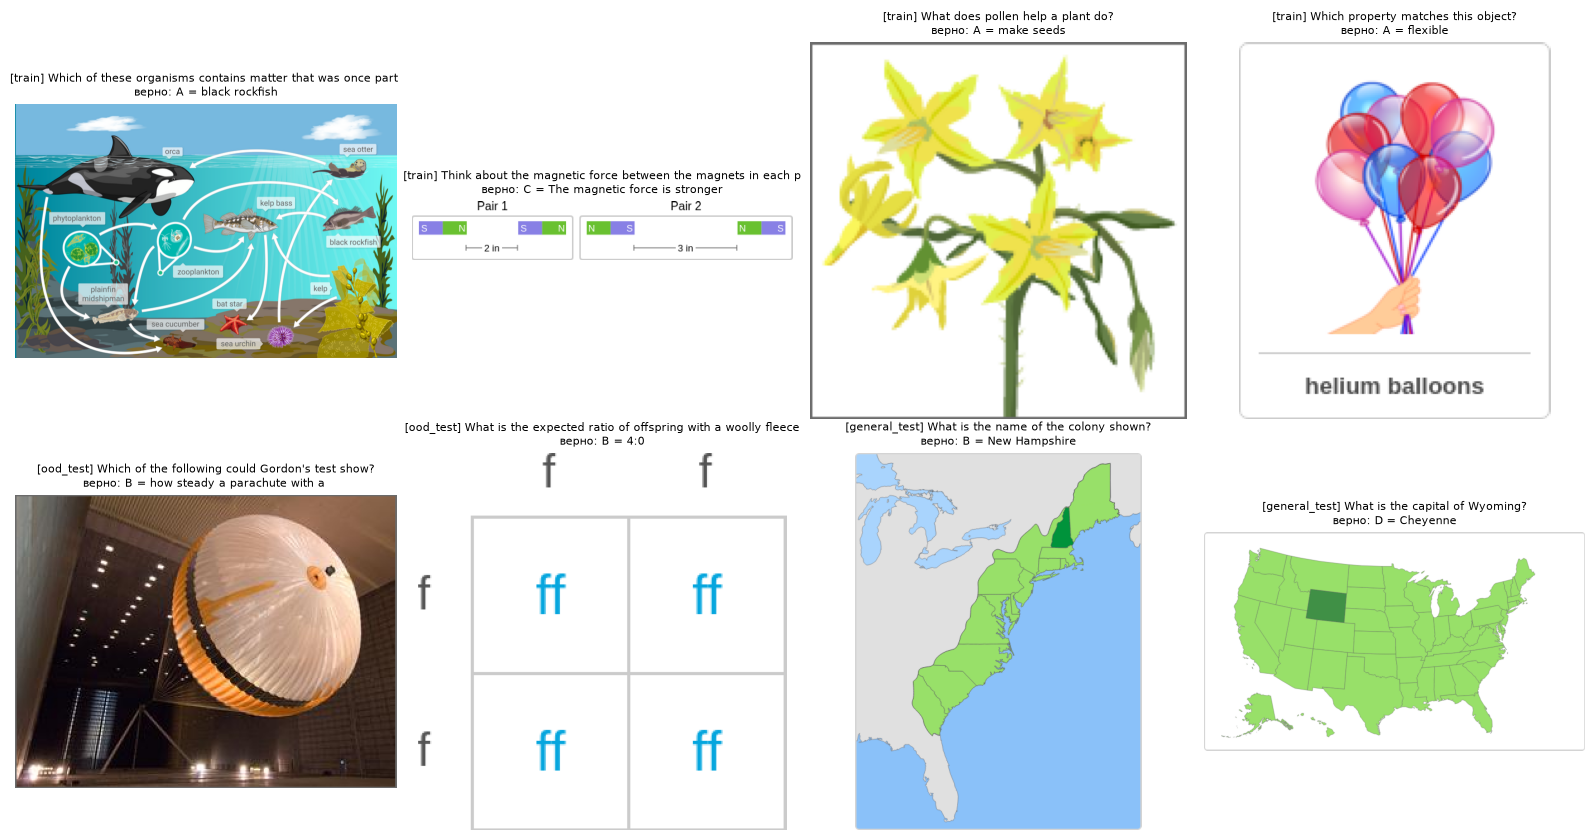

In [3]:
from PIL import Image
import matplotlib.pyplot as plt
profile = {"license": records[0]["license"], "source": records[0]["source_url"], "splits": {}}
for s in EXPECTED:
    rs = [r for r in records if r["split"] == s]
    letters = {}
    for r in rs:
        assert Path(r["image"]).is_file() and r["question"].strip() and r["answer"] in "ABCDE"
        assert r["choices"][r["answer_index"]] == r["choices"][ord(r["answer"]) - 65]   # буква указывает на индекс верного варианта
        letters[r["answer"]] = letters.get(r["answer"], 0) + 1
    sizes = [Image.open(r["image"]).size for r in rs]
    profile["splits"][s] = {"n": len(rs), "answer_letters": dict(sorted(letters.items())), "majority_letter_share": max(letters.values()) / len(rs),
                            "n_choices": dict(sorted({str(len(r["choices"])): sum(len(x["choices"]) == len(r["choices"]) for x in rs) for r in rs}.items())),
                            "grades": sorted({r["grade"] for r in rs}), "subjects": sorted({r["subject"] for r in rs}),
                            "median_image_wh": [int(np.median([w for w, h in sizes])), int(np.median([h for w, h in sizes]))]}
save_json("data_profile.json", profile)
for s, v in profile["splits"].items():
    print(f"{s:13s} n={v['n']:3d} буквы={v['answer_letters']} доля частой={v['majority_letter_share']:.2f} классы={v['grades'][:3]}...")
show = [r for r in records if r["split"] == "train"][:4] + [r for r in records if r["split"] == "ood_test"][:2] + [r for r in records if r["split"] == "general_test"][:2]
fig, axes = plt.subplots(2, 4, figsize=(16, 8.5))
for ax, r in zip(axes.flat, show):
    ax.imshow(Image.open(r["image"])); ax.axis("off")
    q = r["question"].split("\n")[0][:60]
    ax.set_title(f"[{r['split']}] {q}\nверно: {r['answer']} = {r['choices'][r['answer_index']][:30]}", fontsize=8)
fig.tight_layout(); fig.savefig(ARTIFACTS / "data_preview.png", dpi=80); plt.show()

### Экспорт мультимодального датасета

*Вес: 1 балл.*

**Постановка.** Преобразуйте записи в ShareGPT: сообщение пользователя содержит один маркер <image> и вопрос с вариантами, ответ ассистента — правильную букву. Зарегистрируйте train и validation в dataset_info.json.

**Результат.** train.json, validation.json и dataset_info.json.

**Критерий принятия.** Пути изображений разрешаются; роли и столбцы соответствуют формату LLaMA-Factory; test не попал в обучение.


In [4]:
LF_DATA = DATA_ROOT / "lab9_llamafactory"
LF_DATA.mkdir(parents=True, exist_ok=True)
def to_sharegpt(r):
    return {"messages": [{"role": "user", "content": "<image>" + r["question"]}, {"role": "assistant", "content": r["answer"]}],
            "images": [r["image"]], "id": r["id"]}
for split in ("train", "validation"):
    rows = [to_sharegpt(r) for r in records if r["split"] == split]
    (LF_DATA / f"{split}.json").write_text(json.dumps(rows, ensure_ascii=False, indent=1))
dataset_info = {f"lab9_{split}": {"file_name": f"{split}.json", "formatting": "sharegpt",
                                  "columns": {"messages": "messages", "images": "images"},
                                  "tags": {"role_tag": "role", "content_tag": "content", "user_tag": "user", "assistant_tag": "assistant"}}
                for split in ("train", "validation")}
(LF_DATA / "dataset_info.json").write_text(json.dumps(dataset_info, indent=2))
for name in ("train.json", "validation.json", "dataset_info.json"):
    shutil.copy(LF_DATA / name, ARTIFACTS / name)
train_rows = json.loads((LF_DATA / "train.json").read_text())
assert all(m["messages"][0]["content"].count("<image>") == 1 and len(m["images"]) == 1 and Path(m["images"][0]).is_file() for m in train_rows)
test_ids = {r["id"] for r in records if r["split"].endswith("_test")}
assert not test_ids & {m["id"] for m in train_rows}, "test попал в обучение"
print(f"train {len(train_rows)} / validation {len(json.loads((LF_DATA / 'validation.json').read_text()))} диалогов; пример:")
print(json.dumps(train_rows[0], ensure_ascii=False)[:400])

train 512 / validation 64 диалогов; пример:
{"messages": [{"role": "user", "content": "<image>Which of these organisms contains matter that was once part of the phytoplankton?\nA. black rockfish\nB. sea otter\nReturn only the letter of the correct option."}, {"role": "assistant", "content": "A"}], "images": ["/Users/filipp/Desktop/рабочий стол/Вуз/учеба/computer_vision/computer_vision_2026/data/lab9/7059b2a9d6213ab2b6bc531c6adaa60811f86552


### Конфигурация QLoRA SFT

*Вес: 1 балл.*

**Постановка.** Настройте Qwen2.5-VL-3B-Instruct, NF4, LoRA rank 8 и alpha 16, batch 1 с accumulation 16, learning rate 1e-4 и 100 шагов. Включите validation каждые 20 шагов.

**Результат.** sft.yaml.

**Критерий принятия.** YAML содержит реальные идентификаторы данных и модели, включает do_train/do_eval и сохраняет checkpoint; полный режим не ограничен двумя smoke-шагами.


In [5]:
import yaml, hashlib
MODEL_ID = "Qwen/Qwen2.5-VL-3B-Instruct"
MAX_PIXELS = 401408          # ≤ 512 визуальных токенов (512·28·28), одинаково при обучении и инференсе
OUT_DIR = (ARTIFACTS / ("lab9_adapter_smoke" if FAST_DEV_RUN else "lab9_adapter")).resolve()
sft = {"model_name_or_path": MODEL_ID, "trust_remote_code": True,
       "stage": "sft", "do_train": True, "do_eval": True, "finetuning_type": "lora",
       "lora_rank": 8, "lora_alpha": 16, "lora_dropout": 0.05, "lora_target": "all", "freeze_vision_tower": True,
       "quantization_bit": 4, "quantization_method": "bnb", "quantization_type": "nf4", "double_quantization": False,
       "dataset_dir": str(LF_DATA), "dataset": "lab9_train", "eval_dataset": "lab9_validation", "template": "qwen2_vl",
       "cutoff_len": 1024, "image_max_pixels": MAX_PIXELS, "overwrite_cache": True, "preprocessing_num_workers": 1,
       "output_dir": str(OUT_DIR), "logging_steps": 1, "save_steps": 20, "save_total_limit": 10, "plot_loss": True,
       "per_device_train_batch_size": 1, "gradient_accumulation_steps": 16, "learning_rate": 1.0e-4,
       "max_steps": 2 if FAST_DEV_RUN else 100, "lr_scheduler_type": "cosine", "warmup_ratio": 0.1, "max_grad_norm": 1.0,
       "per_device_eval_batch_size": 1, "eval_strategy": "steps", "eval_steps": 2 if FAST_DEV_RUN else 20,
       "seed": SEED, "report_to": "none", "dataloader_num_workers": 0}
fingerprint = hashlib.sha256(json.dumps({k: v for k, v in sft.items() if k != "resume_from_checkpoint"}, sort_keys=True).encode()).hexdigest()[:16]
yaml_path = ARTIFACTS / "sft.yaml"
yaml_path.write_text(yaml.safe_dump(sft, allow_unicode=True, sort_keys=False))
assert sft["do_train"] and sft["do_eval"] and (FAST_DEV_RUN or sft["max_steps"] == 100)
print(yaml_path.read_text()); print("fingerprint конфигурации:", fingerprint)

model_name_or_path: Qwen/Qwen2.5-VL-3B-Instruct
trust_remote_code: true
stage: sft
do_train: true
do_eval: true
finetuning_type: lora
lora_rank: 8
lora_alpha: 16
lora_dropout: 0.05
lora_target: all
freeze_vision_tower: true
quantization_bit: 4
quantization_method: bnb
quantization_type: nf4
double_quantization: false
dataset_dir: /Users/filipp/Desktop/рабочий стол/Вуз/учеба/computer_vision/computer_vision_2026/data/lab9_llamafactory
dataset: lab9_train
eval_dataset: lab9_validation
template: qwen2_vl
cutoff_len: 1024
image_max_pixels: 401408
overwrite_cache: true
preprocessing_num_workers: 1
output_dir: /Users/filipp/Desktop/рабочий стол/Вуз/учеба/computer_vision/computer_vision_2026/labs/lab_09_llamafactory_vlm_sft/artifacts/lab9_adapter
logging_steps: 1
save_steps: 20
save_total_limit: 10
plot_loss: true
per_device_train_batch_size: 1
gradient_accumulation_steps: 16
learning_rate: 0.0001
max_steps: 100
lr_scheduler_type: cosine
warmup_ratio: 0.1
max_grad_norm: 1.0
per_device_eval_b

### Возобновление обучения

*Вес: 1 балл.*

**Постановка.** Реализуйте выбор последнего checkpoint по числовому global step. Отсутствие checkpoint означает новый запуск; существующий должен принадлежать той же конфигурации. Объясните отличие загрузки весов от восстановления состояния оптимизатора.

**Результат.** resume_protocol.json и обновлённый sft.yaml.

**Критерий принятия.** Выбор не основан на лексикографическом порядке; зафиксированы выбранный путь либо null и режим нового/возобновляемого запуска.


In [6]:
def latest_checkpoint(out_dir):
    """Последний checkpoint по числовому global step (checkpoint-100 > checkpoint-20, лексикографически было бы наоборот)."""
    cands = [(int(m.group(1)), p) for p in Path(out_dir).glob("checkpoint-*") if (m := re.fullmatch(r"checkpoint-(\d+)", p.name))]
    return max(cands)[1] if cands else None

fp_file = OUT_DIR / "config_fingerprint.txt"
ckpt = latest_checkpoint(OUT_DIR)
if ckpt is not None and fp_file.exists() and fp_file.read_text().strip() != fingerprint:
    raise RuntimeError(f"{ckpt} принадлежит другой конфигурации — не возобновляю")
mode = "resume" if ckpt is not None else "new"
sft["resume_from_checkpoint"] = str(ckpt) if ckpt else None
yaml_path.write_text(yaml.safe_dump({k: v for k, v in sft.items() if v is not None}, allow_unicode=True, sort_keys=False))
resume = {"selected_checkpoint": str(ckpt) if ckpt else None, "mode": mode, "fingerprint": fingerprint,
          "rule": "max(int(N)) по checkpoint-N; наличие config_fingerprint.txt того же прогона",
          "note": ("Загрузка весов адаптера (adapter_model.safetensors) восстанавливает только параметры LoRA. "
                   "resume_from_checkpoint дополнительно восстанавливает optimizer.pt (моменты AdamW), scheduler.pt, "
                   "rng_state и trainer_state.json (global_step), поэтому траектория обучения продолжается без скачка lr и моментов.")}
save_json("resume_protocol.json", resume)
_check = [Path(f"checkpoint-{n}") for n in (20, 100, 3)]
assert max((int(p.name.split("-")[1]), p) for p in _check)[1].name == "checkpoint-100"
print(json.dumps(resume, ensure_ascii=False, indent=1))

{
 "selected_checkpoint": null,
 "mode": "new",
 "fingerprint": "9af40510b51c0948",
 "rule": "max(int(N)) по checkpoint-N; наличие config_fingerprint.txt того же прогона",
 "note": "Загрузка весов адаптера (adapter_model.safetensors) восстанавливает только параметры LoRA. resume_from_checkpoint дополнительно восстанавливает optimizer.pt (моменты AdamW), scheduler.pt, rng_state и trainer_state.json (global_step), поэтому траектория обучения продолжается без скачка lr и моментов."
}


### Обучение в LLaMA-Factory

*Вес: 1 балл.*

**Постановка.** Выполните llamafactory-cli train с сохранением полного лога. Проверьте фактически выполненное число шагов и наличие обученного адаптера.

**Результат.** lab9_adapter, train.log и version.json.

**Критерий принятия.** Процесс завершился без ошибки; сохранены adapter_model.safetensors и trainer_state.json; запуск с FAST_DEV_RUN=True не принимается за полный эксперимент.


In [7]:
LF_CLI = Path(os.getenv("LLAMAFACTORY_CLI", str(Path.cwd().parents[1] / ".venv-lf" / "bin" / "llamafactory-cli")))
OUT_DIR.mkdir(parents=True, exist_ok=True); fp_file.write_text(fingerprint)
env = {**os.environ, "PYTORCH_ENABLE_MPS_FALLBACK": "1", "TOKENIZERS_PARALLELISM": "false", "DISABLE_VERSION_CHECK": "1",
       "MPLBACKEND": "Agg"}   # inline-бэкенд Jupyter в отдельном окружении LLaMA-Factory недоступен
t0 = time.time()
with open(ARTIFACTS / "train.log", "w") as log:
    proc = subprocess.run([str(LF_CLI), "train", str(yaml_path.resolve())], stdout=log, stderr=subprocess.STDOUT, env=env, cwd=str(Path.cwd()))
train_seconds = time.time() - t0
log_tail = (ARTIFACTS / "train.log").read_text()[-3000:]
assert proc.returncode == 0, log_tail
state = json.loads((OUT_DIR / "trainer_state.json").read_text())
assert (OUT_DIR / "adapter_model.safetensors").exists()
assert state["global_step"] == sft["max_steps"], state["global_step"]
lf_version = subprocess.run([str(LF_CLI), "version"], capture_output=True, text=True, env=env).stdout
version = {"llamafactory": re.search(r"(\d+\.\d+\.\d+\S*)", lf_version).group(1) if re.search(r"(\d+\.\d+\.\d+)", lf_version) else lf_version.strip(),
           "llamafactory_source": "PyPI release llamafactory==0.9.5 (тег v0.9.5)", "base_model": MODEL_ID,
           "base_model_revision": json.loads((OUT_DIR / "adapter_config.json").read_text()).get("revision"),
           "train_seconds": train_seconds, "global_step": state["global_step"], "device": "mps" if torch.backends.mps.is_available() else "cuda",
           "fast_dev_run": FAST_DEV_RUN}
pip_lines = subprocess.run([str(LF_CLI.parent / "python"), "-m", "pip", "freeze"], capture_output=True, text=True).stdout.splitlines()
version["lf_env"] = {l.split("==")[0]: l.split("==")[1] for l in pip_lines if "==" in l and l.split("==")[0].lower() in
                     ("torch", "transformers", "peft", "trl", "accelerate", "bitsandbytes", "datasets")}
save_json("version.json", version)
log_hist = [h for h in state["log_history"] if "loss" in h]
eval_hist = [h for h in state["log_history"] if "eval_loss" in h]
print(f"обучение: {state['global_step']} шагов за {train_seconds / 60:.1f} мин; loss {log_hist[0]['loss']:.3f} → {log_hist[-1]['loss']:.3f}")
print("validation loss по шагам:", [(h["step"], round(h["eval_loss"], 4)) for h in eval_hist])
print(json.dumps(version, indent=1))

обучение: 100 шагов за 231.5 мин; loss 0.208 → 0.111
validation loss по шагам: [(20, 0.1251), (40, 0.1109), (60, 0.1138), (80, 0.1163), (100, 0.1148)]
{
 "llamafactory": "0.9.5",
 "llamafactory_source": "PyPI release llamafactory==0.9.5 (\u0442\u0435\u0433 v0.9.5)",
 "base_model": "Qwen/Qwen2.5-VL-3B-Instruct",
 "base_model_revision": null,
 "train_seconds": 13888.348311901093,
 "global_step": 100,
 "device": "mps",
 "fast_dev_run": false,
 "lf_env": {}
}


### Детерминированный инференс

*Вес: 1 балл.*

**Постановка.** Загрузите исходную модель и процессор. Реализуйте predict: передайте реальное изображение, примените chat template, декодируйте только продолжение после prompt, отключите sampling.

**Результат.** Функция predict.

**Критерий принятия.** Ответ не включает входной вопрос; base и SFT используют один процессор, одинаковые входы и max_new_tokens.


In [ ]:
# Реализуйте это задание по постановке выше.
# Артефакт: процессор, base и детерминированный predict
raise NotImplementedError("Реализуйте это задание в этой ячейке")

### Исходное качество без адаптера

*Вес: 1 балл.*

**Постановка.** Получите предсказания base на всех заранее отделённых ID/OOD/general изображениях. Для каждого ответа сохраните ID, split и эталон.

**Результат.** base_predictions.jsonl.

**Критерий принятия.** Каждый тестовый ID представлен ровно один раз; предсказания получены моделью, не подставлены из правильных ответов.


In [ ]:
# Реализуйте это задание по постановке выше.
# Артефакт: ответы base на ID/OOD/general test
raise NotImplementedError("Реализуйте это задание в этой ячейке")

### Парные ответы после SFT

*Вес: 1 балл.*

**Постановка.** Подключите обученный LoRA и повторите инференс на тех же ID без изменения вопросов и декодирования. Сохраните base и SFT рядом.

**Результат.** predictions.jsonl.

**Критерий принятия.** Пары сопоставлены по ID, а не по случайному порядку; на каждом тесте есть ответы обеих моделей.


In [ ]:
# Реализуйте это задание по постановке выше.
# Артефакт: парные ответы адаптера в artifacts/predictions.jsonl
raise NotImplementedError("Реализуйте это задание в этой ячейке")

### Качество и перенос

*Вес: 1 балл.*

**Постановка.** Посчитайте exact match правильной буквы отдельно по трём тестам. Укажите число примеров и изменение после SFT. Объясните, почему улучшение ID не гарантирует улучшения OOD.

**Результат.** evaluation.json и предметный вывод.

**Критерий принятия.** В знаменателе все примеры соответствующего теста; ошибки формата не исключены; вывод различает ID, OOD и general.


In [ ]:
# Реализуйте это задание по постановке выше.
# Артефакт: artifacts/evaluation.json с n и exact match
raise NotImplementedError("Реализуйте это задание в этой ячейке")

### Творческое мини-исследование

*Бонус: до 1 балла сверх 10.*

**Постановка.** Сформулируйте проверяемую гипотезу о предметном ограничении метода данной лабораторной и проверьте её на дополнительных реальных входах без использования отложенного теста для выбора гипотезы. Сопоставьте результаты с основным экспериментом и объясните расхождения.

**Результат.** Отдельный файл artifacts/bonus.md с гипотезой, протоколом, наблюдениями и выводом.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена по сохранённым предсказаниям или изображениям и приведено воспроизводимое сравнение.

In [ ]:
# Реализуйте творческое мини-исследование по постановке выше.
raise NotImplementedError("Реализуйте бонусное исследование")

## Анализ результатов

Сопоставьте измеренные показатели на фиксированной отложенной выборке, укажите ограничения выборки и разберите ошибки по сохранённым предсказаниям. FAST_DEV_RUN не является основанием для итогового вывода.

## Требования к сдаче

Запустите полный режим, приложите конфигурацию, версии зависимостей, артефакты и инструкции повторного запуска. Не сдавайте фиктивные измерения.